# Figure 3: Reference Frame Preferences

**Paper**: Parodi et al. (2026)

This notebook reproduces Figure 3, which characterizes the spatial reference frame preference of mid-STS neurons across all 5 sessions (1404 units, 2 subjects).

Each unit's encoding model is fit in three reference frames:
- **Allocentric (Allo)**: Position and movement in world coordinates
- **Body-centric (Body)**: Kinematics relative to the body axis
- **Head-centric (Head)**: Kinematics relative to head orientation

The **RF index** for each unit quantifies the relative preference: values near +1 indicate allo-dominant, near -1 indicate ego-dominant.

**Key finding**: ~60% of units are allo-dominant, with M2 showing stronger allocentric preference (74%) than M1 (27%).

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

REPO_ROOT = Path("..").resolve()
sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    'font.size': 12, 'axes.labelsize': 14, 'axes.titlesize': 14,
    'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 11,
    'figure.dpi': 150, 'axes.spines.top': False, 'axes.spines.right': False,
})

SESSION_RENAME = {
    "hedy_0526": "M2_0526", "hedy_0605": "M2_0605",
    "hooke_0525": "M1_0525", "hooke_0609": "M1_0609", "hooke_0613": "M1_0613",
}
SUBJECT_MAP = {"M2_0526": "M2", "M2_0605": "M2", "M1_0525": "M1", "M1_0609": "M1", "M1_0613": "M1"}
FRAME_COLORS = {"allo": "#457B9D", "body": "#E63946", "head": "#F4A261"}

print("Setup complete.")

Setup complete.


## Publication Figure (Production Results)

![Fig 3A: Reference Frame Schematic](../results/production/publication_figures/main/fig3/fig3_reference_frame_schematic.png)

In [2]:
# Load production data using pub_data loaders
from freemat.single_fm.viz.pub_data import load_fig3, load_fig3_rf_index

fig3_df = load_fig3()
rf_index_df = load_fig3_rf_index()

print(f"Fig 3 data: {len(fig3_df)} units across {fig3_df['session_id'].nunique()} sessions")
print(f"RF index data: {len(rf_index_df)} units")
print(f"Columns: {fig3_df.columns.tolist()[:15]}")

Fig 3 data: 1404 units across 5 sessions
RF index data: 1404 units
Columns: ['unit_id', 'session_id', 'unit_bank', 'n_bins', 'bin_s', 'r2_base', 'r2_allo', 'r2_body', 'r2_head', 'delta_r2_allo', 'delta_r2_body', 'delta_r2_head', 'winner_frame', 'alpha_selected', 'alpha_allo']


### Figure 3 Composite (Publication Layout)

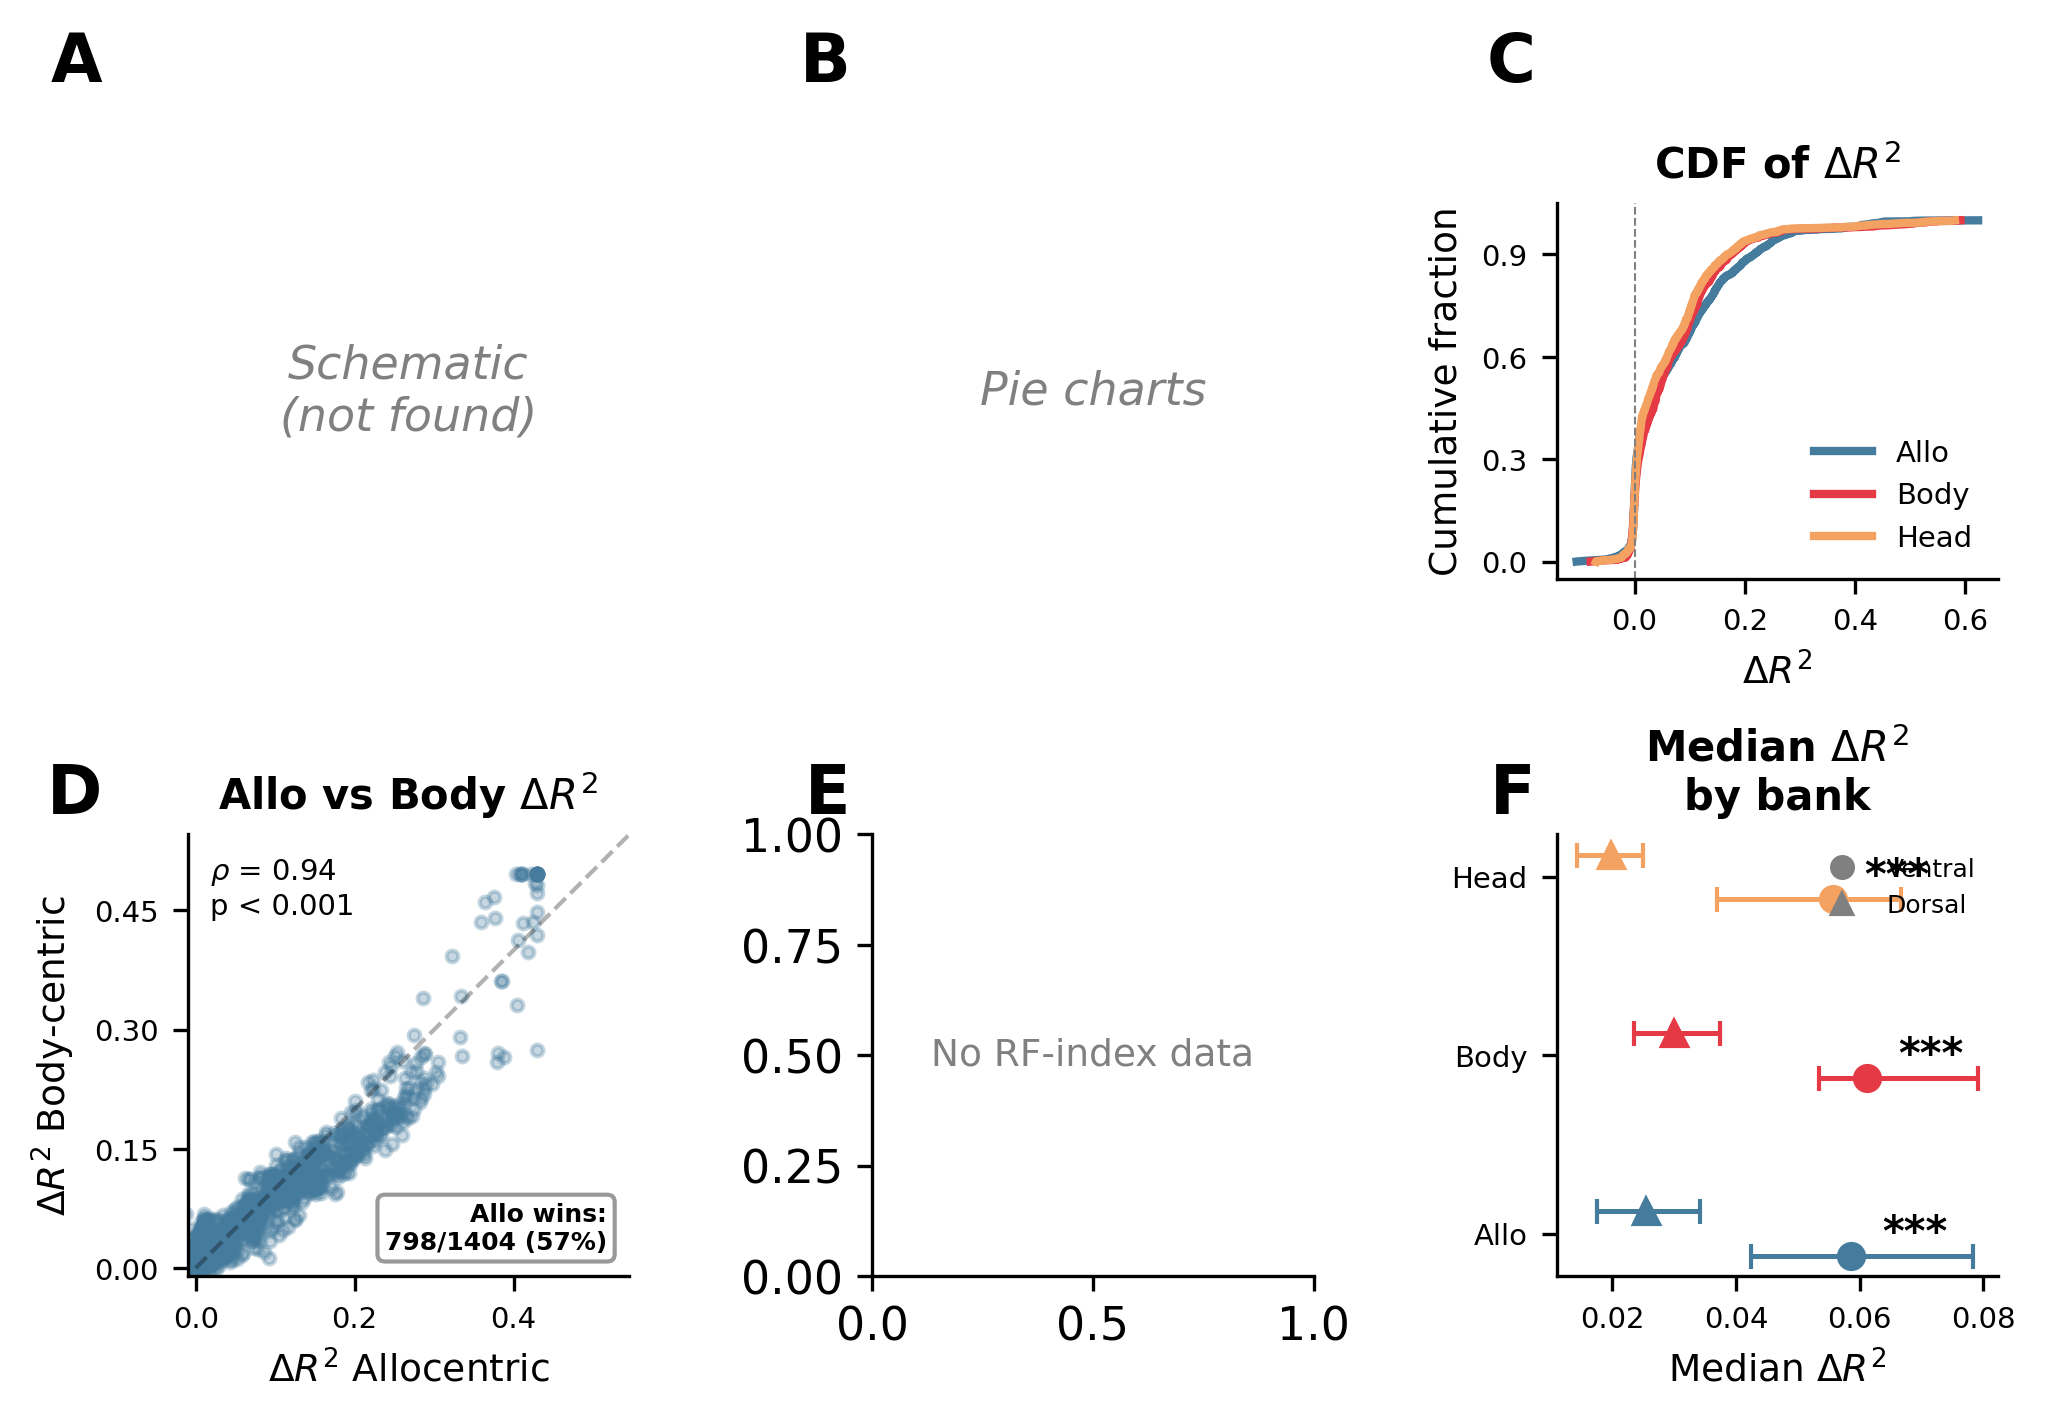

In [3]:
from freemat.single_fm.viz.fig3_composite import fig3_composite

fig = fig3_composite(fig3_df, rf_index_df)
plt.show()